In [6]:
from pathlib import Path
import pandas as pd

PROCESSED = Path("..") / "data" / "processed"

ORDER_DATES = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "review_creation_date", "review_answer_timestamp",
]

orders = pd.read_csv(
    PROCESSED / "orders_clean.csv",
    parse_dates=ORDER_DATES,
    date_format="mixed",
    dtype={"is_late": "boolean", "is_late_timestamp_rule": "boolean"},
)
items = pd.read_csv(
    PROCESSED / "order_items_clean.csv",
    parse_dates=["shipping_limit_date"],
)
sellers = pd.read_csv(PROCESSED / "sellers_clean.csv")

print("orders:", orders.shape, "| items:", items.shape, "| sellers:", sellers.shape)
print("\nis_late dtype:", orders["is_late"].dtype)
print("date dtypes OK:", all(str(orders[c].dtype).startswith("datetime64") for c in ORDER_DATES))
print("\norders columns:\n", list(orders.columns))

orders: (99441, 29) | items: (112650, 11) | sellers: (3095, 5)

is_late dtype: boolean
date dtypes OK: True

orders columns:
 ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'flag_carrier_before_approval', 'flag_delivered_before_carrier', 'delivery_days', 'estimated_days', 'delay_days', 'approval_to_carrier_days', 'carrier_to_customer_days', 'is_late', 'is_late_timestamp_rule', 'in_delivery_population', 'customer_unique_id', 'review_score', 'review_creation_date', 'review_answer_timestamp', 'n_reviews', 'n_items', 'n_sellers', 'items_price', 'items_freight', 'n_payments', 'payment_total']


In [2]:
pop = orders[orders["in_delivery_population"]]

# (description, actual value, expected value from Phase 2)
checks = [
    ("orders rows",                    len(orders),                                   99441),
    ("items rows",                     len(items),                                    112650),
    ("sellers rows",                   len(sellers),                                  3095),
    ("delivery population",            len(pop),                                      96470),
    ("late (calendar-day) in pop",     int(pop["is_late"].sum()),                     6534),
    ("late (timestamp) in pop",        int(pop["is_late_timestamp_rule"].sum()),      7826),
    ("is_late missing in pop",         int(pop["is_late"].isna().sum()),              0),
    ("is_late missing, all orders",    int(orders["is_late"].isna().sum()),           2965),
    ("flag carrier before approval",   int(orders["flag_carrier_before_approval"].sum()),  1359),
    ("flag delivered before carrier",  int(orders["flag_delivered_before_carrier"].sum()), 23),
    ("orders with 2+ reviews",         int((orders["n_reviews"] > 1).sum()),          547),
    ("orders with no review",          int(orders["review_score"].isna().sum()),      768),
    ("orders with no items",           int(orders["n_items"].isna().sum()),           775),
    ("orders with no payment",         int(orders["payment_total"].isna().sum()),     1),
    ("long shipping-limit items",      int(items["flag_long_shipping_limit"].sum()),  239),
    ("unknown-category items",         int((items["category_english"] == "unknown").sum()), 1603),
    ("unknown seller cities",          int((sellers["seller_city_clean"] == "unknown").sum()), 5),
]

report = pd.DataFrame(checks, columns=["check", "actual", "expected"])
report["ok"] = report["actual"] == report["expected"]
print(report.to_string(index=False))

# Money: floats can differ in the last digits after a CSV round trip, so round.
total = round(orders["payment_total"].sum(), 2)
print("\npayment_total sum:", f"{total:,.2f}", "| expected 16,008,872.12 |", total == 16008872.12)
print("customer_unique_id distinct:", orders["customer_unique_id"].nunique(), "| expected 96,096")

assert report["ok"].all(), "A reloaded number does not match Phase 2. Do not continue."
print("\nAll reload checks passed.")

                        check  actual  expected   ok
                  orders rows   99441     99441 True
                   items rows  112650    112650 True
                 sellers rows    3095      3095 True
          delivery population   96470     96470 True
   late (calendar-day) in pop    6534      6534 True
      late (timestamp) in pop    7826      7826 True
       is_late missing in pop       0         0 True
  is_late missing, all orders    2965      2965 True
 flag carrier before approval    1359      1359 True
flag delivered before carrier      23        23 True
       orders with 2+ reviews     547       547 True
        orders with no review     768       768 True
         orders with no items     775       775 True
       orders with no payment       1         1 True
    long shipping-limit items     239       239 True
       unknown-category items    1603      1603 True
        unknown seller cities       5         5 True

payment_total sum: 16,008,872.12 | expected 1

In [3]:
# The population must contain only delivered orders with a delivery date.
print("statuses in population:", pop["order_status"].unique().tolist())
print("null delivery dates in population:", int(pop["order_delivered_customer_date"].isna().sum()))

# Items-to-orders link: every item should match one order (no orphans).
print("items without a matching order:", int((~items["order_id"].isin(orders["order_id"])).sum()))

statuses in population: ['delivered']
null delivery dates in population: 0
items without a matching order: 0


In [4]:
print(orders[ORDER_DATES].dtypes.to_string())

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
review_creation_date                        str
review_answer_timestamp          datetime64[us]


In [7]:
orders["review_creation_date"] = pd.to_datetime(
    orders["review_creation_date"], format="mixed"
)

print(orders[ORDER_DATES].dtypes.to_string())
print("date dtypes OK:", all(str(orders[c].dtype).startswith("datetime64") for c in ORDER_DATES))
print()
print(orders[ORDER_DATES].isna().sum().to_string())

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
review_creation_date             datetime64[us]
review_answer_timestamp          datetime64[us]
date dtypes OK: True

order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
review_creation_date              768
review_answer_timestamp           768


In [8]:
# Month of purchase as a period (e.g. 2017-03).
orders["purchase_month"] = orders["order_purchase_timestamp"].dt.to_period("M")

monthly = orders.groupby("purchase_month").agg(
    orders=("order_id", "size"),
    in_population=("in_delivery_population", "sum"),
)
print("Population: ALL 99,441 orders")
print(monthly.to_string())
print("\nsum of orders:", int(monthly["orders"].sum()), "| months:", len(monthly))

Population: ALL 99,441 orders
                orders  in_population
purchase_month                       
2016-09              4              1
2016-10            324            265
2016-12              1              1
2017-01            800            750
2017-02           1780           1653
2017-03           2682           2546
2017-04           2404           2303
2017-05           3700           3545
2017-06           3245           3135
2017-07           4026           3872
2017-08           4331           4193
2017-09           4285           4150
2017-10           4631           4478
2017-11           7544           7288
2017-12           5673           5513
2018-01           7269           7069
2018-02           6728           6555
2018-03           7211           7003
2018-04           6939           6798
2018-05           6873           6749
2018-06           6167           6096
2018-07           6292           6156
2018-08           6512           6351
2018-09             

In [9]:
pop = orders[orders["in_delivery_population"]]

monthly_late = pop.groupby("purchase_month").agg(
    delivered_orders=("order_id", "size"),
    late_orders=("is_late", "sum"),
)
monthly_late["late_rate_pct"] = (
    monthly_late["late_orders"] / monthly_late["delivered_orders"] * 100
).round(2)

print("Population: 96,470 delivered orders, grouped by PURCHASE month")
print(monthly_late.to_string())
print("\nsum late:", int(monthly_late["late_orders"].sum()), "| expected 6534")

Population: 96,470 delivered orders, grouped by PURCHASE month
                delivered_orders  late_orders  late_rate_pct
purchase_month                                              
2016-09                        1            1          100.0
2016-10                      265            2           0.75
2016-12                        1            0            0.0
2017-01                      750           22           2.93
2017-02                     1653           49           2.96
2017-03                     2546          116           4.56
2017-04                     2303          151           6.56
2017-05                     3545          106           2.99
2017-06                     3135           95           3.03
2017-07                     3872          108           2.79
2017-08                     4193          122           2.91
2017-09                     4150          182           4.39
2017-10                     4478          187           4.18
2017-11               

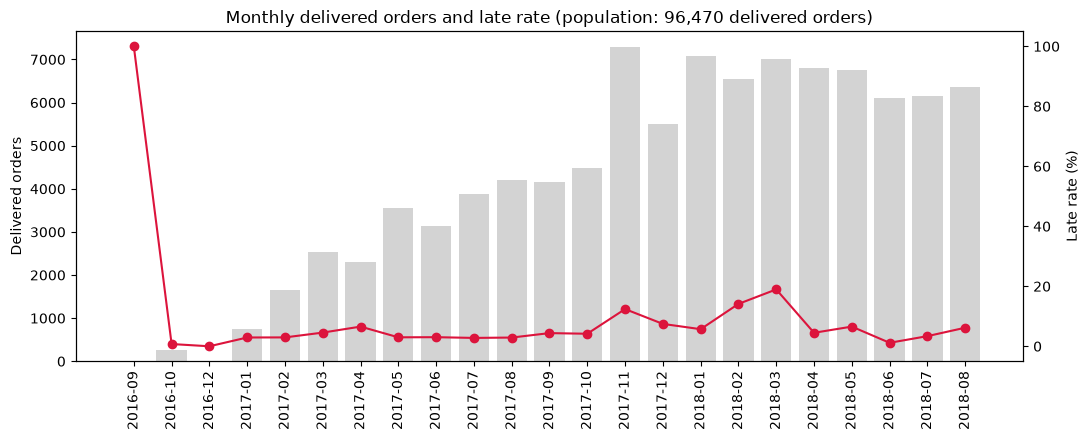

In [10]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(11, 4.5))
x = monthly_late.index.astype(str)

ax1.bar(x, monthly_late["delivered_orders"], color="lightgray")
ax1.set_ylabel("Delivered orders")
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()
ax2.plot(x, monthly_late["late_rate_pct"], color="crimson", marker="o")
ax2.set_ylabel("Late rate (%)")

ax1.set_title("Monthly delivered orders and late rate (population: 96,470 delivered orders)")
plt.tight_layout()
plt.savefig("../reports/figures/monthly_volume_late_rate.png", dpi=150)
plt.show()

In [11]:
RAW = Path("..") / "data" / "raw"
cust = pd.read_csv(RAW / "olist_customers_dataset.csv",
                   usecols=["customer_id", "customer_state"])

# many_to_one: each order's customer_id must match exactly one customer row.
n_before = len(orders)
orders = orders.merge(cust, on="customer_id", how="left", validate="many_to_one")
assert len(orders) == n_before, "Join changed the row count"
print("orders with no state:", int(orders["customer_state"].isna().sum()), "(expected 0)")

# Population: delivered + delivery date, within the accepted trend window.
window = orders["purchase_month"].between(pd.Period("2017-01"), pd.Period("2018-08"))
pop_w = orders[orders["in_delivery_population"] & window]

print("window population:", len(pop_w), "| expected 96,203")
print("late in window:   ", int(pop_w["is_late"].sum()), "| expected 6,531")

orders with no state: 0 (expected 0)
window population: 96203 | expected 96,203
late in window:    6531 | expected 6,531


In [12]:
by_state = pop_w.groupby("customer_state").agg(
    orders=("order_id", "size"),
    late_orders=("is_late", "sum"),
    median_delivery_days=("delivery_days", "median"),
    p90_delivery_days=("delivery_days", lambda s: s.quantile(0.9)),
).round(2)
by_state["late_rate_pct"] = (by_state["late_orders"] / by_state["orders"] * 100).round(2)
by_state["share_of_late_pct"] = (by_state["late_orders"] / by_state["late_orders"].sum() * 100).round(1)

by_state = by_state.sort_values("late_rate_pct", ascending=False)
print("Population: delivered orders, purchases 2017-01 to 2018-08 (96,203)")
print(by_state.to_string())
print("\nsum orders:", int(by_state["orders"].sum()), "| sum late:", int(by_state["late_orders"].sum()))

Population: delivered orders, purchases 2017-01 to 2018-08 (96,203)
                orders  late_orders  median_delivery_days  p90_delivery_days  late_rate_pct  share_of_late_pct
customer_state                                                                                                
AL                 396           85                 22.33              39.61          21.46                1.3
MA                 713          125                 19.18              34.24          17.53                1.9
SE                 332           51                 17.93              35.43          15.36                0.8
PI                 475           66                 16.28              30.10          13.89                1.0
CE                1273          176                 18.17              34.66          13.83                2.7
RR                  40            5                 25.13              53.20           12.5                0.1
BA                3253          396         

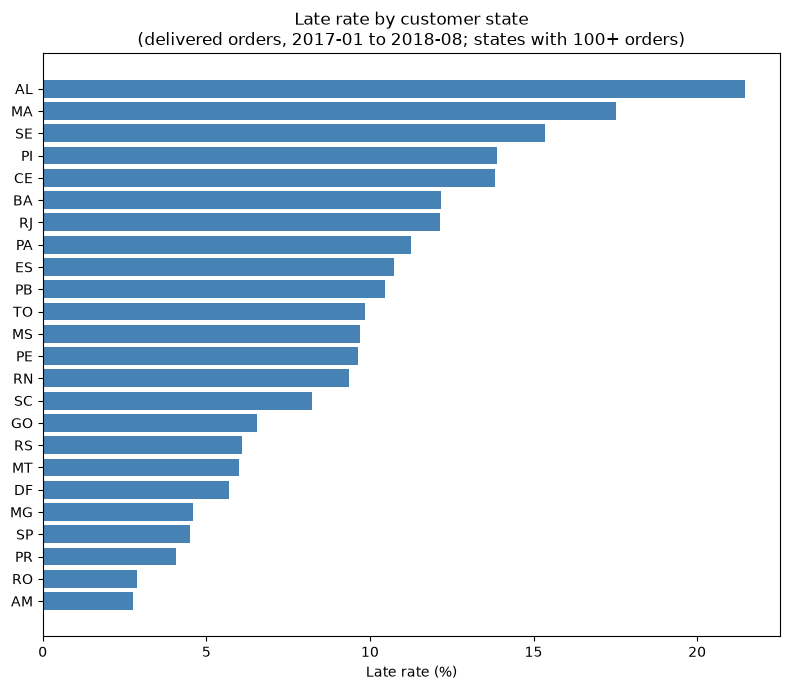

states shown: 24 of 27
orders in hidden states: 187


In [13]:
import matplotlib.pyplot as plt

big = by_state[by_state["orders"] >= 100].sort_values("late_rate_pct")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(big.index, big["late_rate_pct"], color="steelblue")
ax.set_xlabel("Late rate (%)")
ax.set_title("Late rate by customer state\n(delivered orders, 2017-01 to 2018-08; states with 100+ orders)")
plt.tight_layout()
plt.savefig("../reports/figures/late_rate_by_state.png", dpi=150)
plt.show()

print("states shown:", len(big), "of", len(by_state))
print("orders in hidden states:", int(by_state.loc[by_state['orders'] < 100, 'orders'].sum()))

In [14]:
# Orders that have items (775 orders have none).
with_items = orders[orders["n_items"].notna()]
print("orders with items:", len(with_items), "| expected", 99441 - 775)
print("orders with 2+ sellers:", int((with_items["n_sellers"] > 1).sum()))

# Same question inside the analysis population.
print("population orders with 2+ sellers:", int((pop_w["n_sellers"] > 1).sum()),
      "of", int(pop_w["n_sellers"].notna().sum()), "with items")

orders with items: 98666 | expected 98666
orders with 2+ sellers: 1278
population orders with 2+ sellers: 1272 of 96203 with items


In [15]:
# Seller state for each item (many_to_one: each item has one seller).
n = len(items)
items_s = items.merge(sellers[["seller_id", "seller_state"]],
                      on="seller_id", how="left", validate="many_to_one")
assert len(items_s) == n
print("items with no seller state:", int(items_s["seller_state"].isna().sum()), "(expected 0)")

# One row per order: its seller state, defined only if it has exactly one seller.
per_order = items_s.groupby("order_id").agg(
    n_seller_states=("seller_state", "nunique"),
    seller_state=("seller_state", "first"),
)
single = per_order[per_order["n_seller_states"] == 1].reset_index()[["order_id", "seller_state"]]

before = len(pop_w)
pop_s = pop_w.merge(single, on="order_id", how="inner", validate="one_to_one")
print("window population:", before, "| with a single seller state:", len(pop_s))

items with no seller state: 0 (expected 0)
window population: 96203 | with a single seller state: 95696


In [16]:
pop_s = pop_s.copy()
pop_s["same_state"] = pop_s["seller_state"] == pop_s["customer_state"]

route = pop_s.groupby("same_state").agg(
    orders=("order_id", "size"),
    late_orders=("is_late", "sum"),
    median_delivery_days=("delivery_days", "median"),
    p90_delivery_days=("delivery_days", lambda s: s.quantile(0.9)),
).round(2)
route["late_rate_pct"] = (route["late_orders"] / route["orders"] * 100).round(2)

print("Population: delivered, 2017-01 to 2018-08, single seller state")
print(route.to_string())

Population: delivered, 2017-01 to 2018-08, single seller state
            orders  late_orders  median_delivery_days  p90_delivery_days  late_rate_pct
same_state                                                                             
False        61207         4966                 12.81              26.29           8.11
True         34489         1562                  6.53              14.23           4.53


In [17]:
# Many sellers are in SP, so check the pattern for SP-origin orders only.
sp_origin = pop_s[pop_s["seller_state"] == "SP"]
top_dest = sp_origin["customer_state"].value_counts().head(8).index
sp_tbl = sp_origin[sp_origin["customer_state"].isin(top_dest)].groupby("customer_state").agg(
    orders=("order_id", "size"),
    median_delivery_days=("delivery_days", "median"),
    late_rate_pct=("is_late", lambda s: round(s.mean() * 100, 2)),
).sort_values("median_delivery_days")

print("Orders from SP sellers, top 8 destination states")
print(sp_tbl.to_string())
print("\nSP-origin orders in total:", len(sp_origin))

Orders from SP sellers, top 8 destination states
                orders  median_delivery_days  late_rate_pct
customer_state                                             
SP               30586              6.535666           4.67
MG                7394             10.793576            5.3
PR                3102             11.097940           4.45
RJ                8111             12.841123           14.2
ES                1457             13.599340          12.35
SC                2317             13.862650           9.58
RS                3569             13.890787           6.67
BA                2300             17.694416          12.91

SP-origin orders in total: 68052


In [18]:
# Is RJ's lateness concentrated in Nov 2017 and Feb-Mar 2018?
rj = sp_origin[sp_origin["customer_state"] == "RJ"]
print(rj.groupby("purchase_month").agg(
    orders=("order_id", "size"),
    late_rate_pct=("is_late", lambda s: round(s.mean() * 100, 1)),
).to_string())

                orders  late_rate_pct
purchase_month                       
2017-01             57            3.5
2017-02            136            3.7
2017-03            226            4.9
2017-04            216            6.0
2017-05            292            3.1
2017-06            278            3.2
2017-07            375            1.9
2017-08            377            2.4
2017-09            398            6.5
2017-10            437            8.0
2017-11            707           32.0
2017-12            492           29.9
2018-01            571           12.8
2018-02            567           39.2
2018-03            588           42.2
2018-04            558            5.7
2018-05            548            8.2
2018-06            451            1.3
2018-07            407            2.2
2018-08            430            4.2


In [19]:
pop_w = pop_w.copy()
# Compare RJ and SP with all other destination states combined.
pop_w["dest_group"] = pop_w["customer_state"].where(
    pop_w["customer_state"].isin(["RJ", "SP"]), "Other")

tbl = (pop_w.groupby(["purchase_month", "dest_group"])["is_late"]
            .mean().mul(100).round(1).unstack())
print("Late rate (%) by purchase month. Population: delivered, 2017-01 to 2018-08 (96,203)")
print(tbl.to_string())

Late rate (%) by purchase month. Population: delivered, 2017-01 to 2018-08 (96,203)
dest_group      Other    RJ   SP
purchase_month                  
2017-01           2.9   3.3  2.8
2017-02           2.8   3.5  3.0
2017-03           6.4   4.3  2.3
2017-04           6.2   6.5  7.0
2017-05           2.0   2.8  4.3
2017-06           2.8   3.3  3.3
2017-07           3.5   3.1  1.8
2017-08           3.6   3.0  2.0
2017-09           5.2   5.1  3.1
2017-10           4.1   6.9  3.3
2017-11          13.0  26.0  7.0
2017-12           6.5  24.0  3.1
2018-01           5.9  13.1  3.4
2018-02          14.3  34.0  7.3
2018-03          23.7  34.5  9.4
2018-04           7.2   4.8  1.7
2018-05           9.0   6.9  4.3
2018-06           1.6   1.3  0.7
2018-07           3.3   2.4  3.7
2018-08           2.7   5.8  9.0


In [20]:
# Single-seller orders only: the late outcome can be attributed to one seller.
single_ids = pop_w.loc[pop_w["n_sellers"] == 1, "order_id"]
print("single-seller orders:", len(single_ids), "| expected 94,931")

order_seller = (items[items["order_id"].isin(single_ids)]
                .groupby("order_id", as_index=False)["seller_id"].first())

ps = pop_w.merge(order_seller, on="order_id", how="inner", validate="one_to_one")
assert len(ps) == len(single_ids), "Join changed the row count"
print("rows after join:", len(ps))

single-seller orders: 94931 | expected 94,931
rows after join: 94931


In [21]:
MIN_ORDERS = 30  # judgment, not a statistical rule

per_seller = ps.groupby("seller_id").agg(
    orders=("order_id", "size"),
    late_orders=("is_late", "sum"),
    median_delivery_days=("delivery_days", "median"),
).round(2)
per_seller["late_rate_pct"] = (per_seller["late_orders"] / per_seller["orders"] * 100).round(2)
per_seller = per_seller.join(sellers.set_index("seller_id")["seller_state"])

big = per_seller[per_seller["orders"] >= MIN_ORDERS]
print("sellers with orders:", len(per_seller), "| with", MIN_ORDERS, "+ orders:", len(big))
print(f"share of orders covered by those sellers: {big['orders'].sum() / per_seller['orders'].sum():.1%}")
print(f"overall late rate in this population: {ps['is_late'].mean():.2%}")

print("\nHighest late rate (sellers with 30+ orders):")
print(big.sort_values("late_rate_pct", ascending=False).head(10).to_string())

# Concentration: how much of all lateness comes from the top 10 sellers by late count?
top10 = per_seller.sort_values("late_orders", ascending=False).head(10)
print(f"\nTop 10 sellers by late orders: {int(top10['late_orders'].sum())} of "
      f"{int(per_seller['late_orders'].sum())} late orders")

sellers with orders: 2925 | with 30 + orders: 614
share of orders covered by those sellers: 83.2%
overall late rate in this population: 6.87%

Highest late rate (sellers with 30+ orders):
                                  orders  late_orders  median_delivery_days  late_rate_pct seller_state
seller_id                                                                                              
ad781527c93d00d89a11eecd9dcad7c1      33           12                 25.00          36.36           SP
ede0c03645598cdfc63ca8237acbe73d      43           14                 15.28          32.56           SP
54965bbe3e4f07ae045b90b0b8541f52      72           22                 16.63          30.56           PR
2a1348e9addc1af5aaa619b1a3679d6b      45           13                 13.80          28.89           MG
835f0f7810c76831d6c7d24c7a646d4d      40           11                 18.28           27.5           SP
beadbee30901a7f61d031b6b686095ad      63           15                  9.60         

In [22]:
worst = big.sort_values("late_rate_pct", ascending=False).head(10).index
spike = ps["purchase_month"].isin([pd.Period(m) for m in ["2017-11","2017-12","2018-02","2018-03"]])
chk = ps[ps["seller_id"].isin(worst)].groupby("seller_id").apply(
    lambda d: pd.Series({
        "orders": len(d),
        "share_in_spike_months_%": round(spike.loc[d.index].mean() * 100, 1),
        "late_rate_outside_spike_%": round(d.loc[~spike.loc[d.index], "is_late"].mean() * 100, 1),
    }), include_groups=False)
print("Overall share of orders in the 4 spike months:", round(spike.mean()*100, 1), "%")
print(chk.to_string())

Overall share of orders in the 4 spike months: 27.5 %
                                  orders  share_in_spike_months_%  late_rate_outside_spike_%
seller_id                                                                                   
2a1348e9addc1af5aaa619b1a3679d6b    45.0                     13.3                       28.2
54965bbe3e4f07ae045b90b0b8541f52    72.0                     56.9                        0.0
71039d19d4303bf9054d69e9a9236699    34.0                     61.8                       23.1
712e6ed8aa4aa1fa65dab41fed5737e4    77.0                     59.7                        6.5
835f0f7810c76831d6c7d24c7a646d4d    40.0                     10.0                       19.4
a49928bcdf77c55c6d6e05e09a9b4ca5    93.0                     37.6                       10.3
ad781527c93d00d89a11eecd9dcad7c1    33.0                     36.4                       19.0
beadbee30901a7f61d031b6b686095ad    63.0                      0.0                       23.8
ede0c03645598cdf

In [23]:
rv = pop_w[pop_w["review_score"].notna()]
print("Population: delivered, 2017-01 to 2018-08 (96,203). With a review:", len(rv),
      "| without:", len(pop_w) - len(rv))

by_late = rv.groupby("is_late").agg(
    orders=("order_id", "size"),
    mean_score=("review_score", "mean"),
    pct_1_star=("review_score", lambda s: (s == 1).mean() * 100),
    pct_5_star=("review_score", lambda s: (s == 5).mean() * 100),
).round(2)
print(by_late.to_string())

print("\nScore distribution (% of orders), late vs on time:")
print((pd.crosstab(rv["is_late"], rv["review_score"], normalize="index") * 100).round(1).to_string())

Population: delivered, 2017-01 to 2018-08 (96,203). With a review: 95560 | without: 643
         orders  mean_score  pct_1_star  pct_5_star
is_late                                            
False     89182        4.29        6.60       62.28
True       6378        2.27       53.76       16.54

Score distribution (% of orders), late vs on time:
review_score   1.0  2.0   3.0   4.0   5.0
is_late                                  
False          6.6  2.6   8.1  20.4  62.3
True          53.8  8.7  10.9  10.2  16.5


In [24]:
bins = [-1000, -0.0001, 0, 3, 7, 14, 1000]
labels = ["early", "on date", "1-3 days late", "4-7 days late", "8-14 days late", "15+ days late"]
# Whole days past the estimate, using the calendar-day rule from Phase 2.
days_late = (rv["order_delivered_customer_date"].dt.normalize()
             - rv["order_estimated_delivery_date"]).dt.days
rv = rv.assign(lateness=pd.cut(days_late, bins=bins, labels=labels))

print(rv.groupby("lateness", observed=True).agg(
    orders=("order_id", "size"),
    mean_score=("review_score", "mean"),
    pct_1_star=("review_score", lambda s: (s == 1).mean() * 100),
).round(2).to_string())
print("\nrows binned:", int(rv["lateness"].notna().sum()), "| expected", len(rv))

                orders  mean_score  pct_1_star
lateness                                      
early            87902        4.29        6.57
on date           1280        4.03        8.52
1-3 days late     1851        3.29       25.12
4-7 days late     1748        2.10       58.58
8-14 days late    1446        1.67       70.61
15+ days late     1333        1.72       68.94

rows binned: 95560 | expected 95560


In [25]:
stages = ["approval_to_carrier_days", "carrier_to_customer_days", "delivery_days"]
# Stage durations are null on flagged rows (Phase 2 rule), so counts differ.
summary = pd.DataFrame({
    "orders": pop_w[stages].notna().sum(),
    "median": pop_w[stages].median(),
    "p90": pop_w[stages].quantile(0.9),
}).round(2)
print(summary.to_string())

# Same stages, on-time vs late.
print("\nMedian days by stage:")
print(pop_w.groupby("is_late")[stages].median().round(2).to_string())

                          orders  median    p90
approval_to_carrier_days   94838    1.84   5.99
carrier_to_customer_days   96183    7.10  18.91
delivery_days              96203   10.21  23.06

Median days by stage:
         approval_to_carrier_days  carrier_to_customer_days  delivery_days
is_late                                                                   
False                        1.79                      6.95           9.80
True                         3.07                     26.20          31.25


In [26]:
pop_ids = pop_w["order_id"]
it = items[items["order_id"].isin(pop_ids)].copy()

print("population orders:", len(pop_ids), "| items in them:", len(it))
print("distinct orders in items:", it["order_id"].nunique(), "(must equal", len(pop_ids), ")")
print("price sum:", f"{it['price'].sum():,.2f}", "| freight sum:", f"{it['freight_value'].sum():,.2f}")

population orders: 96203 | items in them: 109872
distinct orders in items: 96203 (must equal 96203 )
price sum: 13,179,777.95 | freight sum: 2,191,963.14


In [27]:
cat = it.groupby("category_english").agg(
    items=("order_id", "size"),
    revenue=("price", "sum"),
    freight=("freight_value", "sum"),
    median_price=("price", "median"),
)
cat["freight_pct_of_price"] = (cat["freight"] / cat["revenue"] * 100).round(1)
cat["share_of_revenue_pct"] = (cat["revenue"] / cat["revenue"].sum() * 100).round(1)

top = cat.sort_values("revenue", ascending=False).head(12).round(2)
print("Population: items in delivered orders, 2017-01 to 2018-08")
print(top.to_string())
print(f"\nTop 12 categories' share of revenue: {top['share_of_revenue_pct'].sum():.1f}%")
print("categories:", len(cat), "| 'unknown' share of revenue:",
      cat.loc["unknown", "share_of_revenue_pct"], "%")

Population: items in delivered orders, 2017-01 to 2018-08
                       items     revenue    freight  median_price  freight_pct_of_price  share_of_revenue_pct
category_english                                                                                             
health_beauty           9422  1229557.50  178202.28         79.90                  14.5                   9.3
watches_gifts           5853  1163187.91   98035.36        128.90                   8.4                   8.8
bed_bath_table         10945  1022955.77  201646.91         79.57                  19.7                   7.8
sports_leisure          8413   952661.40  162910.75         77.90                  17.1                   7.2
computers_accessories   7631   887944.60  143797.21         81.99                  16.2                   6.7
furniture_decor         8095   706237.17  167193.40         65.49                  23.7                   5.4
housewares              6783   614341.62  142508.09         59

In [28]:
# Orders whose items all share one category.
n_cat = it.groupby("order_id")["category_english"].nunique()
single_cat_ids = n_cat[n_cat == 1].index
print("single-category orders:", len(single_cat_ids), "of", len(n_cat))

one_cat = (it[it["order_id"].isin(single_cat_ids)]
           .groupby("order_id", as_index=False)["category_english"].first())
pc = pop_w.merge(one_cat, on="order_id", how="inner", validate="one_to_one")
assert len(pc) == len(single_cat_ids)

MIN_ORDERS = 300  # judgment, to avoid noisy rates
by_cat = pc.groupby("category_english").agg(
    orders=("order_id", "size"),
    late_orders=("is_late", "sum"),
    median_delivery_days=("delivery_days", "median"),
)
by_cat["late_rate_pct"] = (by_cat["late_orders"] / by_cat["orders"] * 100).round(2)
big = by_cat[by_cat["orders"] >= MIN_ORDERS].sort_values("late_rate_pct", ascending=False)

print(f"overall late rate here: {pc['is_late'].mean():.2%} | categories with {MIN_ORDERS}+ orders: {len(big)}")
print(big.round(2).head(8).to_string())
print("...")
print(big.round(2).tail(5).to_string())

single-category orders: 95425 of 96203
overall late rate here: 6.83% | categories with 300+ orders: 32
                       orders  late_orders  median_delivery_days  late_rate_pct
category_english                                                               
audio                     340           41                 10.81          12.06
home_confort              342           35                 11.46          10.23
baby                     2707          224                 10.08           8.27
office_furniture         1233          101                 18.87           8.19
furniture_living_room     398           31                 12.16           7.79
electronics              2493          192                 11.03            7.7
musical_instruments       603           46                 10.61           7.63
health_beauty            8539          646                  9.57           7.57
...
                     orders  late_orders  median_delivery_days  late_rate_pct
category_englis

In [29]:
w = pd.read_csv(Path("..") / "data" / "processed" / "order_items_clean.csv",
                usecols=["order_id", "order_item_id", "product_weight_g_clean"])
it_w = it.merge(w, on=["order_id", "order_item_id"], how="left", validate="one_to_one",
                suffixes=("", "_dup"))
# Order weight = sum of item weights (one row per item, quantity not available beyond item rows).
ow = it_w.groupby("order_id")["product_weight_g_clean"].agg(["sum", "count", "size"])
ow = ow[ow["count"] == ow["size"]]  # keep orders where every item has a weight
ow = ow["sum"].rename("order_weight_g").reset_index()

pw = pop_w.merge(ow, on="order_id", how="inner", validate="one_to_one")
pw["weight_band"] = pd.qcut(pw["order_weight_g"], 5, duplicates="drop")
print("orders with a known weight:", len(pw), "of", len(pop_w))
print(pw.groupby("weight_band", observed=True).agg(
    orders=("order_id", "size"),
    late_rate_pct=("is_late", lambda s: round(s.mean() * 100, 2)),
    median_delivery_days=("delivery_days", "median"),
).to_string())

orders with a known weight: 96181 of 96203
                    orders  late_rate_pct  median_delivery_days
weight_band                                                    
(1.999, 250.0]       20454            6.1              9.426383
(250.0, 500.0]       18278           7.04              9.972338
(500.0, 1100.0]      19010           6.25             10.128640
(1100.0, 2800.0]     19348           7.05             10.436285
(2800.0, 184400.0]   19091           7.56             11.188611


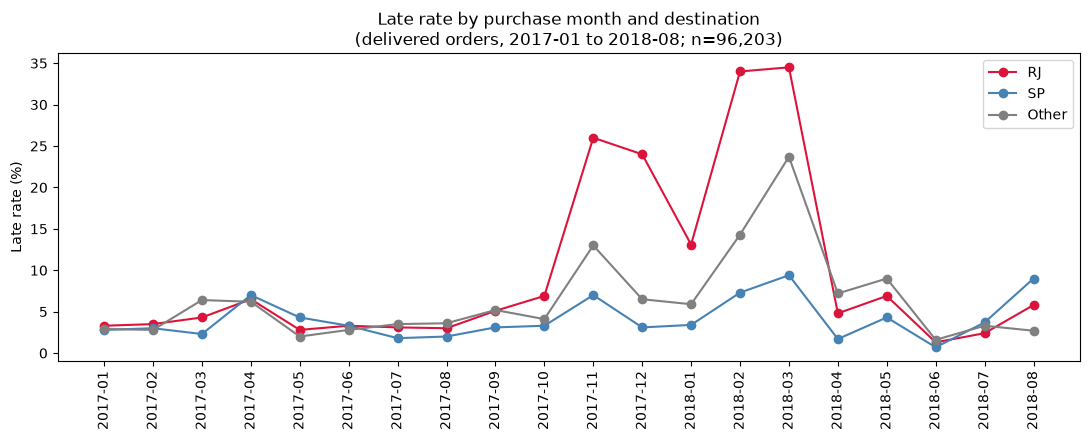

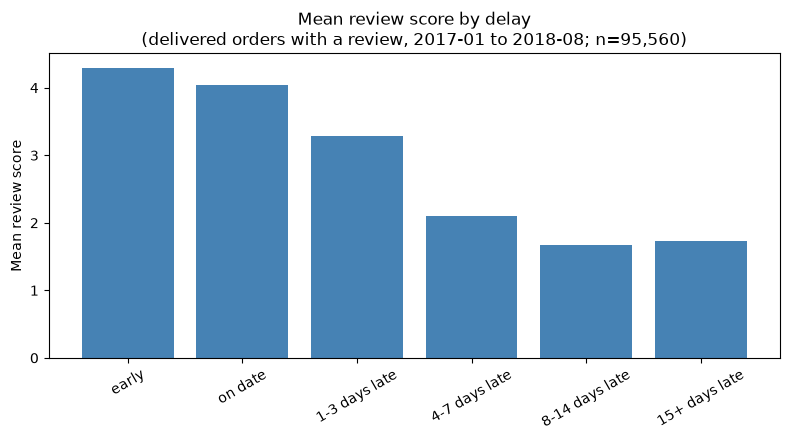

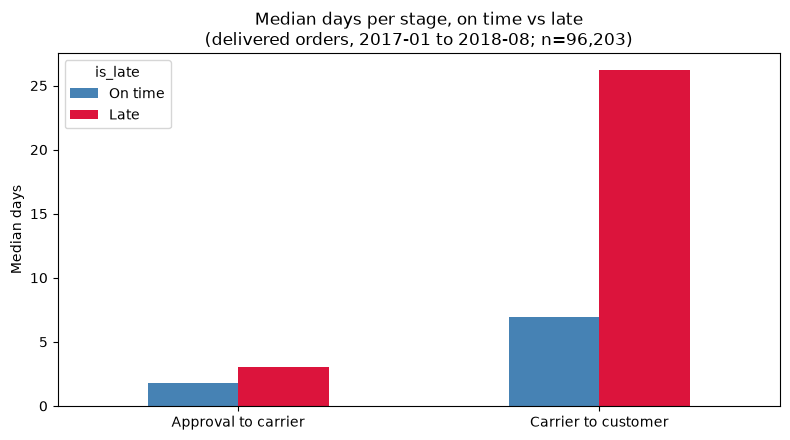

In [30]:
import matplotlib.pyplot as plt
FIG = Path("..") / "reports" / "figures"

# 1) Late rate by month: RJ vs SP vs other states (Cell 14 table)
fig, ax = plt.subplots(figsize=(11, 4.5))
x = tbl.index.astype(str)
for col, color in [("RJ", "crimson"), ("SP", "steelblue"), ("Other", "gray")]:
    ax.plot(x, tbl[col], marker="o", label=col, color=color)
ax.set_ylabel("Late rate (%)")
ax.tick_params(axis="x", rotation=90)
ax.legend()
ax.set_title("Late rate by purchase month and destination\n(delivered orders, 2017-01 to 2018-08; n=96,203)")
plt.tight_layout()
plt.savefig(FIG / "late_rate_by_month_destination.png", dpi=150)
plt.show()

# 2) Review score by size of delay (Cell 18 'rv' has the 'lateness' column)
rs = rv.groupby("lateness", observed=True)["review_score"].mean()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(rs.index.astype(str), rs.values, color="steelblue")
ax.set_ylabel("Mean review score")
ax.tick_params(axis="x", rotation=30)
ax.set_title("Mean review score by delay\n(delivered orders with a review, 2017-01 to 2018-08; n=95,560)")
plt.tight_layout()
plt.savefig(FIG / "review_score_by_delay.png", dpi=150)
plt.show()

# 3) Median days per stage: on time vs late
stages = ["approval_to_carrier_days", "carrier_to_customer_days"]
st = pop_w.groupby("is_late")[stages].median()
ax = st.rename(index={False: "On time", True: "Late"}).T.rename(
    index={"approval_to_carrier_days": "Approval to carrier",
           "carrier_to_customer_days": "Carrier to customer"}).plot(
    kind="bar", figsize=(8, 4.5), color=["steelblue", "crimson"], rot=0)
ax.set_ylabel("Median days")
ax.set_title("Median days per stage, on time vs late\n(delivered orders, 2017-01 to 2018-08; n=96,203)")
plt.tight_layout()
plt.savefig(FIG / "stage_days_on_time_vs_late.png", dpi=150)
plt.show()